# 03 · Exploratory Data Analysis (Train only)

**What this notebook covers**

- Target distribution
- Cancellation rate by hotel, lead time, deposit type, market segment and channel
- Guest history and special requests
- Leakage checks on fields recorded after booking (parking, room changes, country)
- Seasonality and year-over-year drift
- Feature association ranking (mutual information, Cramér's V, Spearman)
- EDA insight log

## 1. Environment setup
### 1.1 Imports

In [1]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

### 1.2 Configuration, seed and paths

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "03"
MIN_SUPPORT = 100        # hide groups smaller than this in rate charts
TOP_N_COUNTRIES = 15

# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


### 1.3 Shared constants, helpers and plotting style

In [3]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [4]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

### 1.4 EDA helper functions
- `wilson_interval`: a confidence interval for a proportion that stays inside [0, 1] and
  behaves well for small groups (better than the normal approximation).
- `rate_table`: cancellation rate per group with n and CI.
- `plot_rate_bars`: horizontal bars sorted by rate, with CI whiskers and the overall
  rate as a reference line.

In [5]:
def wilson_interval(successes, n, z: float = 1.96):
    successes, n = np.asarray(successes, dtype=float), np.asarray(n, dtype=float)
    p = np.divide(successes, n, out=np.zeros_like(successes), where=n > 0)
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def rate_table(frame: pd.DataFrame, column: str, min_support: int = MIN_SUPPORT) -> pd.DataFrame:
    grouped = frame.groupby(column, observed=True)[TARGET].agg(n="size", cancellations="sum")
    grouped["rate"] = grouped["cancellations"] / grouped["n"]
    grouped["ci_low"], grouped["ci_high"] = wilson_interval(grouped["cancellations"], grouped["n"])
    return grouped[grouped["n"] >= min_support].sort_values("rate", ascending=False)


def plot_rate_bars(table: pd.DataFrame, title: str, overall_rate: float, ax=None, label_fmt="{:.0%}"):
    ax = ax or plt.subplots(figsize=(8, max(2.6, 0.42 * len(table) + 1)))[1]
    ordered = table.sort_values("rate")
    labels = [str(i) for i in ordered.index]
    errors = np.vstack([ordered["rate"] - ordered["ci_low"], ordered["ci_high"] - ordered["rate"]])
    bars = ax.barh(labels, ordered["rate"], xerr=errors, color=COLORS["not_canceled"], height=0.62,
                   error_kw={"ecolor": COLORS["ink_muted"], "elinewidth": 1, "capsize": 2})
    ax.axvline(overall_rate, color=COLORS["neutral"], linestyle="--", linewidth=1.2, label=f"Overall {overall_rate:.1%}")
    ax.bar_label(bars, labels=[f"{label_fmt.format(r)}  (n={n:,})" for r, n in zip(ordered["rate"], ordered["n"])],
                 padding=6, color=COLORS["ink_muted"], fontsize=8.5)
    ax.set_xlim(0, min(1.0, ordered["ci_high"].max() * 1.45))
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.set_xlabel("Cancellation rate (95% Wilson CI)")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    return ax


INSIGHTS = []  # (theme, finding, evidence, modelling_implication) rows for the EDA insight log


def log_insight(theme: str, finding: str, evidence: str, implication: str) -> None:
    INSIGHTS.append({"theme": theme, "finding": finding, "evidence": evidence, "modelling_implication": implication})

## 2. Load the Train split (and verify it)

In [6]:
split_manifest = load_json(PATHS["artifacts"] / "split_manifest.json")
train_path = PATHS["splits"] / "train.csv"
assert sha256_file(train_path) == split_manifest["file_hashes"]["train"], "Train split changed - re-run notebook 02."

train = read_frame(train_path)
OVERALL_RATE = train[TARGET].mean()
print(f"Train rows: {len(train):,} | cancellation rate {OVERALL_RATE:.2%}")

Train rows: 60,996 | cancellation rate 27.28%


### 2.1 Derived helper columns for analysis only
These columns exist only inside this notebook to make plots readable. The real feature
engineering lives in notebook 04.

In [7]:
MONTH_ORDER = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
LEAD_TIME_BINS = [-1, 7, 30, 90, 180, 365, np.inf]
LEAD_TIME_LABELS = ["0-7d", "8-30d", "31-90d", "91-180d", "181-365d", ">365d"]

eda = train.assign(
    lead_time_band=pd.cut(train["lead_time"], bins=LEAD_TIME_BINS, labels=LEAD_TIME_LABELS),
    total_nights=train["stays_in_weekend_nights"] + train["stays_in_week_nights"],
    has_previous_cancellation=np.where(train["previous_cancellations"] > 0, "Yes", "No"),
    has_parking_request=np.where(train["required_car_parking_spaces"] > 0, "Yes", "No"),
    special_requests=train["total_of_special_requests"].clip(upper=3).astype(str).replace({"3": "3+"}),
    booking_changes_band=train["booking_changes"].clip(upper=3).astype(str).replace({"3": "3+"}),
    is_portugal=np.where(train["country"] == "PRT", "PRT", "Other"),
    room_changed=np.where(train["reserved_room_type"] != train["assigned_room_type"], "Changed", "Same"),
    arrival_month=pd.Categorical(train["arrival_date_month"], categories=MONTH_ORDER, ordered=True),
)

## 3. Target distribution
The post-dedup class balance is the reference for every metric: the PR-AUC of a
no-skill model equals this prevalence.

Saved figure -> reports/figures/03_target_distribution.png


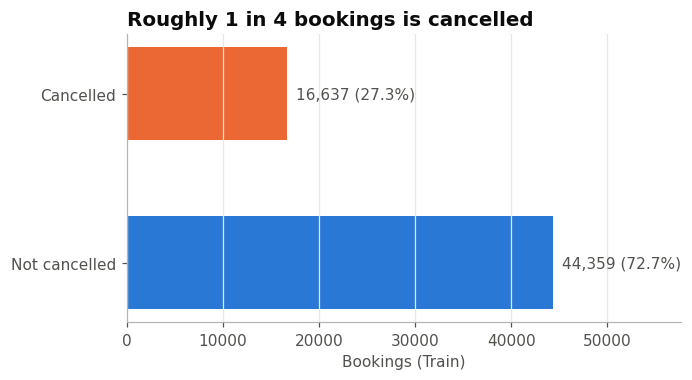

In [8]:
counts = eda[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.barh(["Not cancelled", "Cancelled"], counts.values,
               color=[COLORS["not_canceled"], COLORS["canceled"]], height=0.55)
ax.bar_label(bars, labels=[f"{v:,} ({v / counts.sum():.1%})" for v in counts.values], padding=6, color=COLORS["ink_muted"])
ax.set_xlim(0, counts.max() * 1.3)
ax.set_xlabel("Bookings (Train)")
ax.set_title("Roughly 1 in 4 bookings is cancelled", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "target_distribution")
plt.show()

log_insight("Target", f"Cancellation prevalence {OVERALL_RATE:.2%} after de-duplication",
            f"{counts[1]:,} of {counts.sum():,} Train bookings",
            "Accuracy baseline is ~72.7%; report PR-AUC / recall, never accuracy alone.")

## 4. Hotel type

Saved figure -> reports/figures/03_rate_by_hotel.png


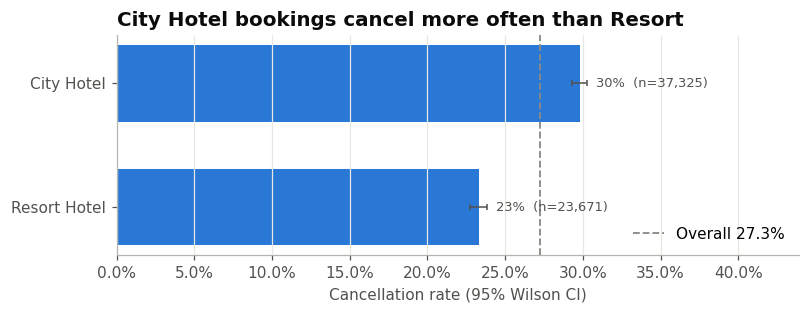

,n,cancellations,rate,ci_low,ci_high
hotel,,,,,
City Hotel,37325,11122,0.298,0.2934,0.3026
Resort Hotel,23671,5515,0.233,0.2276,0.2384


In [9]:
hotel_rates = rate_table(eda, "hotel")
plot_rate_bars(hotel_rates, "City Hotel bookings cancel more often than Resort", OVERALL_RATE)
save_figure(plt.gcf(), "rate_by_hotel")
plt.show()
log_insight("Hotel", "City Hotel cancels more than Resort Hotel",
            "; ".join(f"{i}: {r:.1%}" for i, r in hotel_rates["rate"].items()),
            "Keep `hotel`; consider hotel-specific thresholds (plan F-05).")
hotel_rates.round(4)

## 5. Lead time
### 5.1 Distribution by outcome
The density overlay shows *shape* differences independent of class size; the x-axis is
clipped at the 99th percentile for readability.

Saved figure -> reports/figures/03_lead_time_density.png


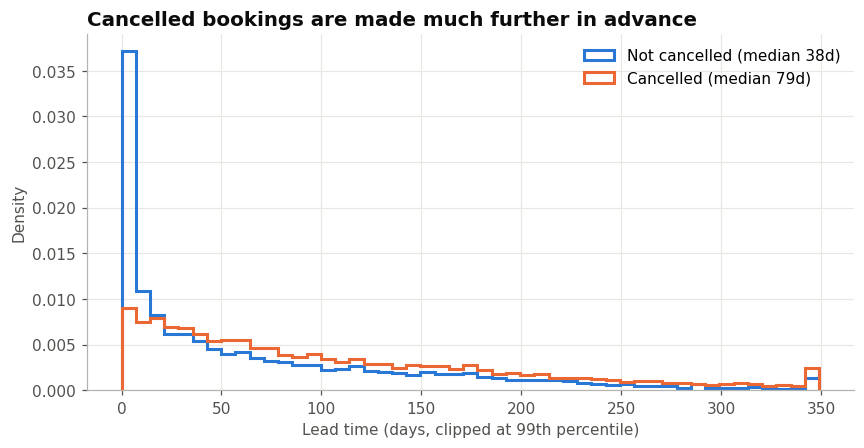

In [10]:
clip_at = eda["lead_time"].quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(0, clip_at, 50)
for label, name in [(0, "not_canceled"), (1, "canceled")]:
    values = eda.loc[eda[TARGET] == label, "lead_time"].clip(upper=clip_at)
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=COLORS[name],
            label=f"{'Cancelled' if label else 'Not cancelled'} (median {values.median():.0f}d)")
ax.set_xlabel("Lead time (days, clipped at 99th percentile)")
ax.set_ylabel("Density")
ax.set_title("Cancelled bookings are made much further in advance", loc="left")
ax.legend()
save_figure(fig, "lead_time_density")
plt.show()

### 5.2 Cancellation rate by lead-time band
Banding shows the rate climbs steadily with lead time. This is a monotonic relationship that
linear models can exploit and trees split on easily.

Saved figure -> reports/figures/03_rate_by_lead_time_band.png


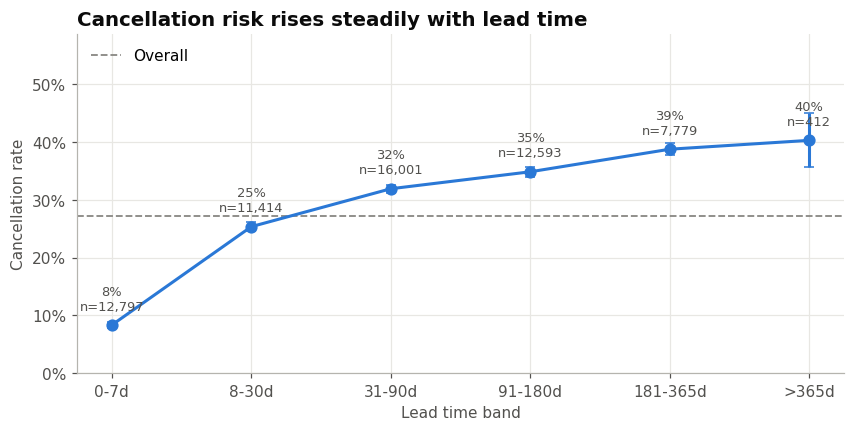

In [11]:
lead_rates = rate_table(eda, "lead_time_band", min_support=1).reindex(LEAD_TIME_LABELS)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(lead_rates.index, lead_rates["rate"],
            yerr=[lead_rates["rate"] - lead_rates["ci_low"], lead_rates["ci_high"] - lead_rates["rate"]],
            color=COLORS["not_canceled"], marker="o", markersize=7, capsize=3, linewidth=2)
for x, (rate, n) in enumerate(zip(lead_rates["rate"], lead_rates["n"])):
    ax.annotate(f"{rate:.0%}\nn={n:,}", (x, rate), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=8.5, color=COLORS["ink_muted"])
ax.axhline(OVERALL_RATE, color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="Overall")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_ylim(0, lead_rates["ci_high"].max() * 1.3)
ax.set_xlabel("Lead time band")
ax.set_ylabel("Cancellation rate")
ax.set_title("Cancellation risk rises steadily with lead time", loc="left")
ax.legend(loc="upper left")
save_figure(fig, "rate_by_lead_time_band")
plt.show()

log_insight("Lead time", "Cancellation rate increases monotonically with lead time",
            f"{lead_rates['rate'].iloc[0]:.1%} (0-7d) -> {lead_rates['rate'].iloc[-1]:.1%} (>365d)",
            "Keep raw lead_time (trees) and scale it for linear models / SVM.")

### 5.3 Lead time × hotel interaction
Two series on one shared axis: does the lead-time effect differ by hotel? Diverging
slopes would justify interaction-capable models (trees/boosting).

Saved figure -> reports/figures/03_lead_time_by_hotel.png


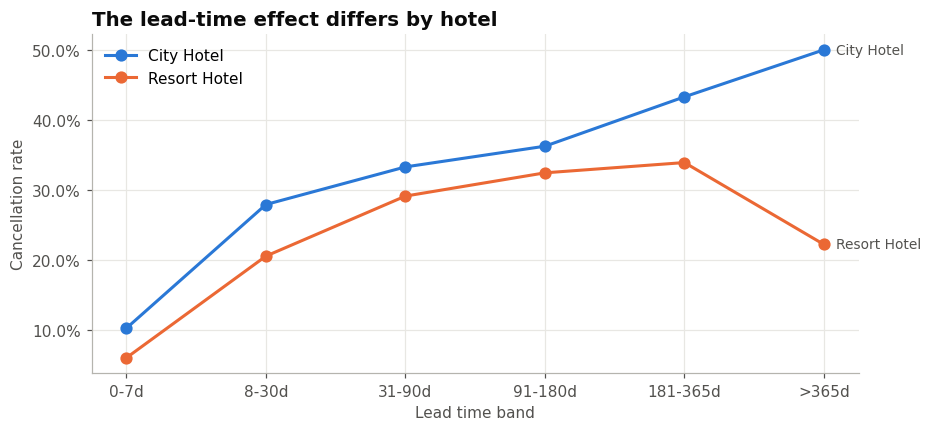

In [12]:
interaction = (
    eda.groupby(["hotel", "lead_time_band"], observed=True)[TARGET].mean().unstack(0).reindex(LEAD_TIME_LABELS)
)
fig, ax = plt.subplots(figsize=(9, 4))
for color, hotel in zip(SERIES_COLORS, interaction.columns):
    ax.plot(interaction.index, interaction[hotel], marker="o", markersize=7, color=color, label=hotel)
    ax.annotate(hotel, (len(interaction) - 1, interaction[hotel].iloc[-1]), textcoords="offset points",
                xytext=(8, 0), va="center", color=COLORS["ink_muted"], fontsize=9)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_xlabel("Lead time band")
ax.set_ylabel("Cancellation rate")
ax.set_title("The lead-time effect differs by hotel", loc="left")
ax.legend(loc="upper left")
save_figure(fig, "lead_time_by_hotel")
plt.show()

## 6. Booking channel and commercial terms
### 6.1 Deposit type, market segment, distribution channel, customer type
After de-duplication `Non Refund` covers far fewer bookings than the raw figure in the docs
(plan issue I-01), so the anomaly is re-examined with its CI.

Saved figure -> reports/figures/03_rate_by_deposit_type.png


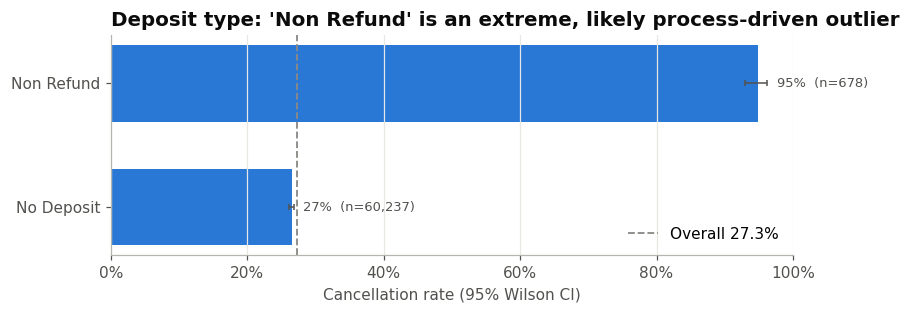

Saved figure -> reports/figures/03_rate_by_market_segment.png


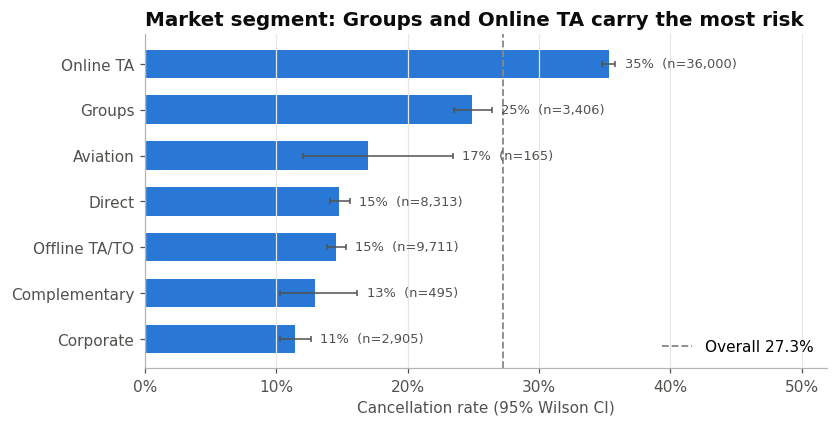

Saved figure -> reports/figures/03_rate_by_distribution_channel.png


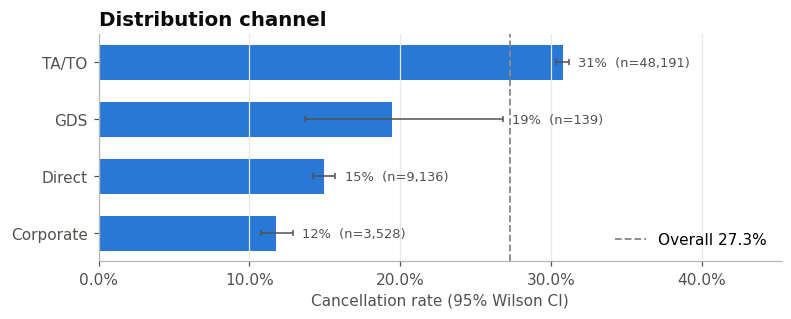

Saved figure -> reports/figures/03_rate_by_customer_type.png


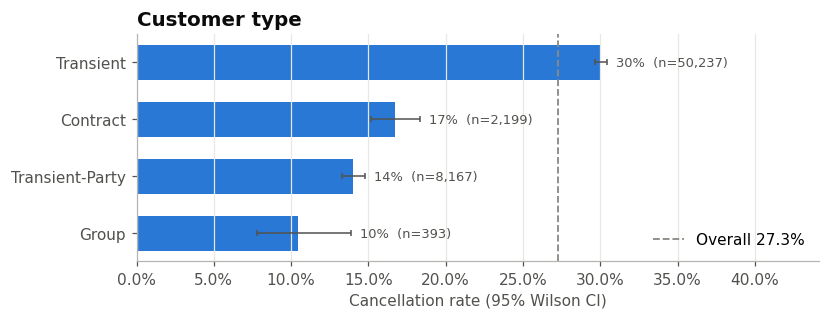

In [13]:
for column, title in [
    ("deposit_type", "Deposit type: 'Non Refund' is an extreme, likely process-driven outlier"),
    ("market_segment", "Market segment: Groups and Online TA carry the most risk"),
    ("distribution_channel", "Distribution channel"),
    ("customer_type", "Customer type"),
]:
    table = rate_table(eda, column)
    plot_rate_bars(table, title, OVERALL_RATE)
    save_figure(plt.gcf(), f"rate_by_{column}")
    plt.show()
    table.round(4).to_csv(PATHS["tables"] / f"03_rate_by_{column}.csv")

deposit_rates = rate_table(eda, "deposit_type", min_support=1)
log_insight("Deposit", "Non Refund deposits show a near-deterministic cancellation rate",
            f"Non Refund: {deposit_rates.loc['Non Refund', 'rate']:.1%} (n={deposit_rates.loc['Non Refund', 'n']:,})",
            "Keep feature but report as a probable channel/process confound, not a causal effect (decision #11).")

## 7. Guest history
Past behaviour is typically the strongest signal: guests who cancelled before tend to
cancel again; repeat guests tend to honour bookings.

Saved figure -> reports/figures/03_rate_by_guest_history.png


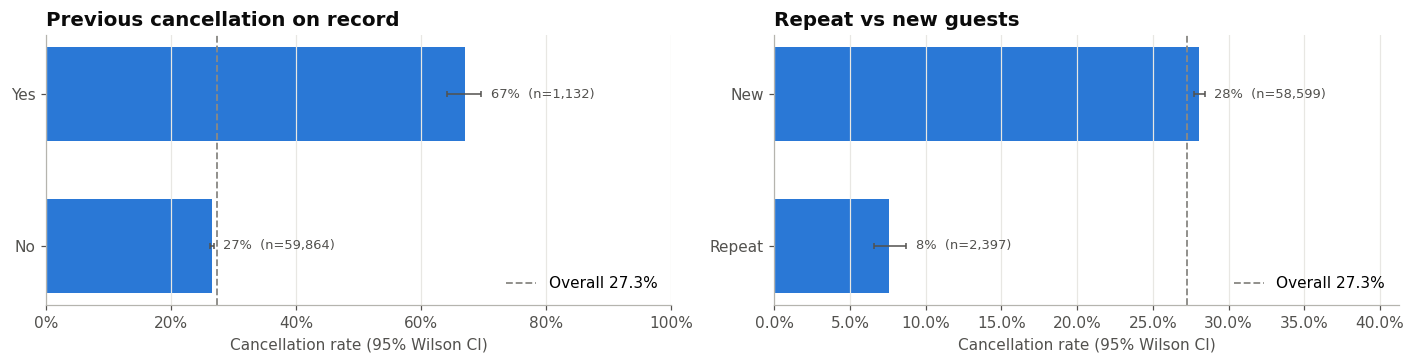

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
history_prev = rate_table(eda, "has_previous_cancellation", min_support=1)
history_repeat = rate_table(eda.assign(is_repeated_guest=eda["is_repeated_guest"].map({0: "New", 1: "Repeat"})),
                            "is_repeated_guest", min_support=1)
plot_rate_bars(history_prev, "Previous cancellation on record", OVERALL_RATE, ax=axes[0])
plot_rate_bars(history_repeat, "Repeat vs new guests", OVERALL_RATE, ax=axes[1])
fig.tight_layout()
save_figure(fig, "rate_by_guest_history")
plt.show()

log_insight("History", "Guests with a prior cancellation cancel far more often",
            f"Yes: {history_prev.loc['Yes', 'rate']:.1%} vs No: {history_prev.loc['No', 'rate']:.1%}",
            "Keep previous_cancellations; engineer prior_cancellation_rate (notebook 04).")
log_insight("History", "Repeat guests cancel less",
            f"Repeat: {history_repeat.loc['Repeat', 'rate']:.1%} vs New: {history_repeat.loc['New', 'rate']:.1%}",
            "Keep is_repeated_guest.")

## 8. Leakage-suspect fields (timing audit)
Fields that may be recorded *after* the booking is made (at check-in or closer to
arrival) inflate offline metrics but are unavailable at decision time. We look for
"too good to be true" patterns.

### 8.1 Car-parking requests
A rate of exactly 0 % across thousands of bookings is not a plausible behavioural
effect; it strongly suggests the field is filled in at arrival (only guests who show up
get a parking space recorded).

Saved figure -> reports/figures/03_rate_by_parking_request.png


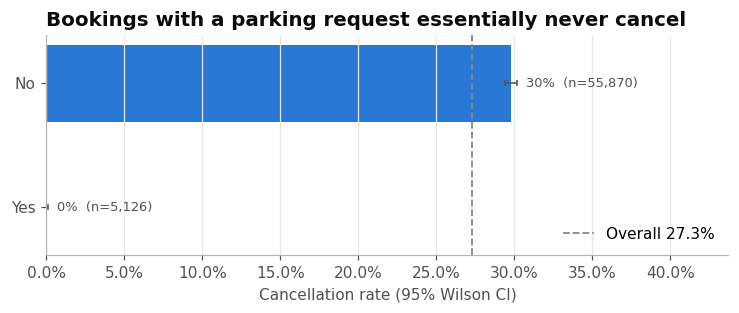

,n,cancellations,rate,ci_low,ci_high
has_parking_request,,,,,
No,55870,16637,0.2978,0.294,0.3016
Yes,5126,0,0.0000,0.000,0.0007


In [15]:
parking = rate_table(eda, "has_parking_request", min_support=1)
plot_rate_bars(parking, "Bookings with a parking request essentially never cancel", OVERALL_RATE)
save_figure(plt.gcf(), "rate_by_parking_request")
plt.show()

log_insight("Leakage audit", "required_car_parking_spaces > 0 has ~0% cancellation",
            f"{parking.loc['Yes', 'cancellations']} cancellations in {parking.loc['Yes', 'n']:,} bookings",
            "Probable arrival-time field: exclude from day-zero variant (proposed decision #22).")
parking.round(4)

### 8.2 Booking changes, room re-assignment and waiting list
These fields accumulate during the booking's lifetime (decisions #6, #12). They are kept
only in the *full-lifecycle* variant.

Saved figure -> reports/figures/03_rate_by_lifecycle_fields.png


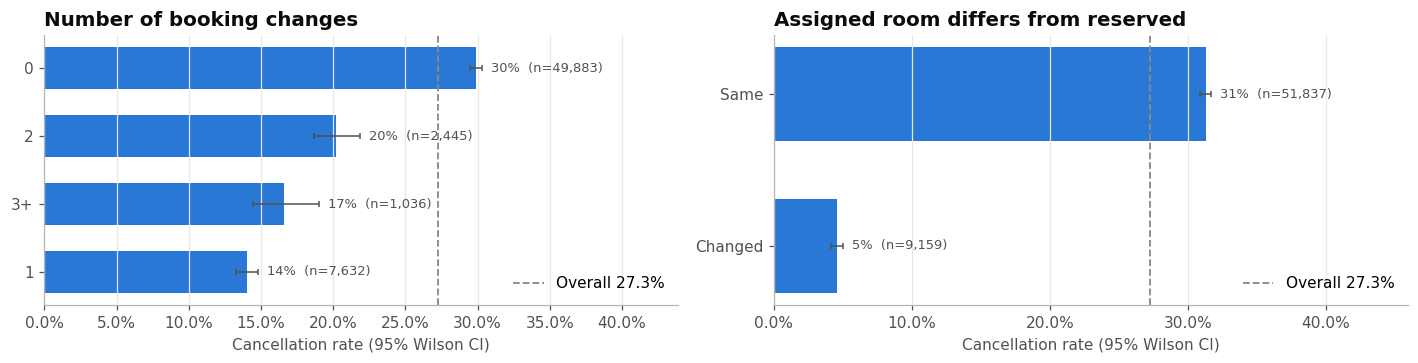

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
plot_rate_bars(rate_table(eda, "booking_changes_band", min_support=1), "Number of booking changes", OVERALL_RATE, ax=axes[0])
plot_rate_bars(rate_table(eda, "room_changed", min_support=1), "Assigned room differs from reserved", OVERALL_RATE, ax=axes[1])
fig.tight_layout()
save_figure(fig, "rate_by_lifecycle_fields")
plt.show()

room_rates = rate_table(eda, "room_changed", min_support=1)
log_insight("Leakage audit", "Room re-assignment is associated with far fewer cancellations",
            f"Changed: {room_rates.loc['Changed', 'rate']:.1%} vs Same: {room_rates.loc['Same', 'rate']:.1%}",
            "Re-assignment usually happens at check-in: full-lifecycle variant only.")

### 8.3 Country: testing the "nationality confirmed at check-in" hypothesis
Hotels often confirm a guest's nationality only at check-in; if so, cancelled bookings
would keep a default country (often the hotel's home country, PRT). Evidence for this:
PRT having a much *higher* cancellation rate than other countries. This is a
hypothesis to flag (plan I-15 / F-03), not a conclusion.

Saved figure -> reports/figures/03_rate_by_country.png


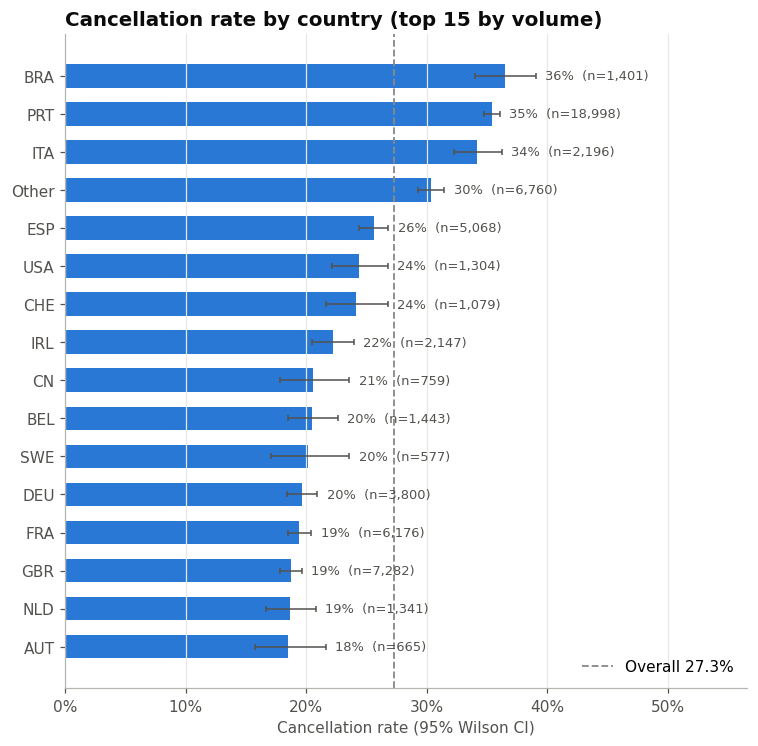

In [17]:
top_countries = eda["country"].value_counts().head(TOP_N_COUNTRIES).index
country_rates = rate_table(eda.assign(country_grouped=eda["country"].where(eda["country"].isin(top_countries), "Other")),
                           "country_grouped")
plot_rate_bars(country_rates, f"Cancellation rate by country (top {TOP_N_COUNTRIES} by volume)", OVERALL_RATE)
save_figure(plt.gcf(), "rate_by_country")
plt.show()

prt = rate_table(eda, "is_portugal", min_support=1)
log_insight("Leakage audit", "PRT bookings cancel more often than all other countries",
            f"PRT: {prt.loc['PRT', 'rate']:.1%} vs Other: {prt.loc['Other', 'rate']:.1%}",
            "Possible late-recorded nationality; run a with/without-country ablation (plan F-03). Fairness check in notebook 13.")

## 9. Engagement signals: special requests
Guests who add special requests are more invested in the stay.

Saved figure -> reports/figures/03_rate_by_special_requests.png


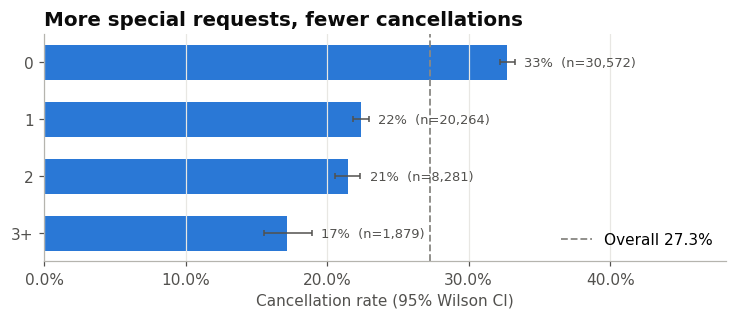

In [18]:
requests = rate_table(eda, "special_requests", min_support=1)
plot_rate_bars(requests, "More special requests, fewer cancellations", OVERALL_RATE)
save_figure(plt.gcf(), "rate_by_special_requests")
plt.show()
log_insight("Engagement", "Cancellation rate falls as special requests increase",
            "; ".join(f"{i}: {r:.1%}" for i, r in requests["rate"].sort_index().items()),
            "Keep total_of_special_requests (note: requests can also be added after booking).")

## 10. Seasonality and temporal drift
### 10.1 Monthly volume and monthly cancellation rate
Two separate panels (never a dual axis): volume on the left, rate on the right.

Saved figure -> reports/figures/03_seasonality.png


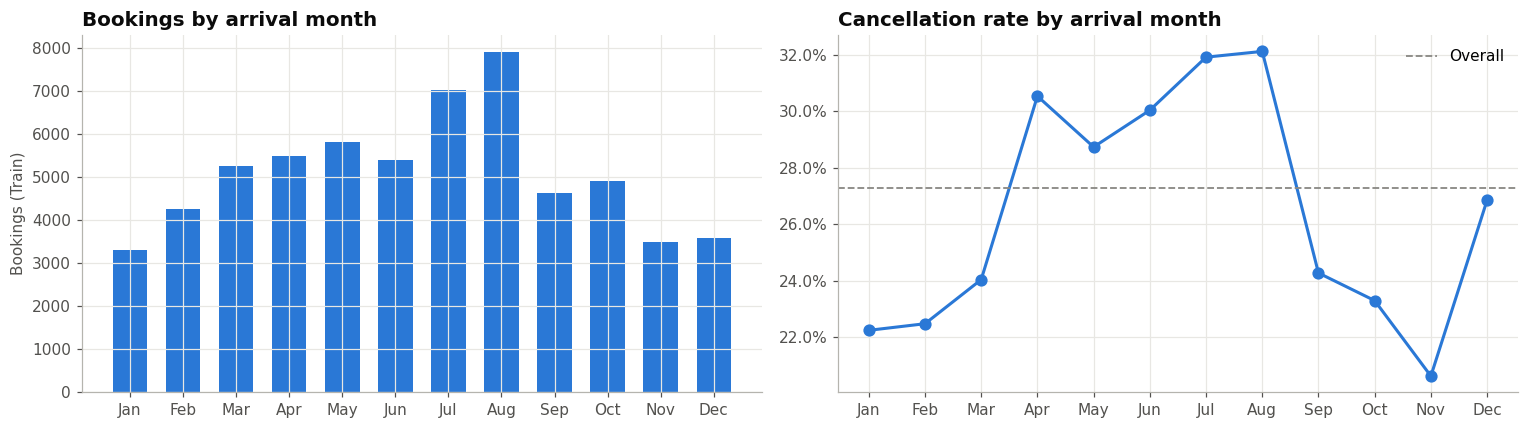

In [19]:
monthly = eda.groupby("arrival_month", observed=True)[TARGET].agg(n="size", rate="mean").reindex(MONTH_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar([m[:3] for m in monthly.index], monthly["n"], color=COLORS["not_canceled"], width=0.65)
axes[0].set_title("Bookings by arrival month", loc="left")
axes[0].set_ylabel("Bookings (Train)")
axes[1].plot([m[:3] for m in monthly.index], monthly["rate"], marker="o", markersize=7, color=COLORS["not_canceled"])
axes[1].axhline(OVERALL_RATE, color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="Overall")
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[1].set_title("Cancellation rate by arrival month", loc="left")
axes[1].legend()
fig.tight_layout()
save_figure(fig, "seasonality")
plt.show()

### 10.2 Year-over-year drift
A rising cancellation rate over the years means a random split is optimistic for a
deployment that predicts the *future*. This motivates excluding `arrival_date_year`
(proposed decision #23) and the temporal check in notebook 14.

Saved figure -> reports/figures/03_rate_by_year.png


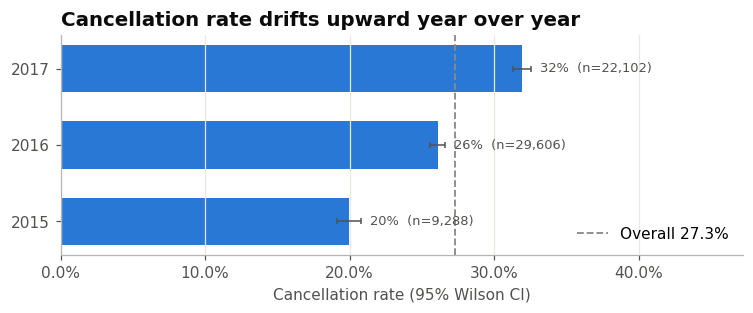

In [20]:
yearly = rate_table(eda.assign(arrival_year=eda["arrival_date_year"].astype(str)), "arrival_year", min_support=1).sort_index()
plot_rate_bars(yearly, "Cancellation rate drifts upward year over year", OVERALL_RATE)
save_figure(plt.gcf(), "rate_by_year")
plt.show()
log_insight("Drift", "Cancellation rate increases from 2015 to 2017",
            "; ".join(f"{i}: {r:.1%}" for i, r in yearly["rate"].items()),
            "Exclude arrival_date_year from features; add temporal robustness check (notebook 14).")

## 11. Price (ADR) by outcome
ADR is clipped at the 99th percentile for display only (the model-side cap is learned
in notebook 04).

Saved figure -> reports/figures/03_adr_density.png


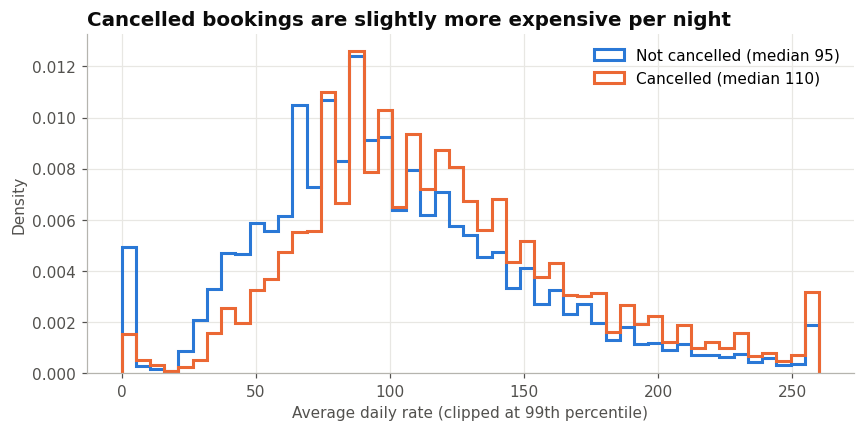

In [21]:
adr_clip = eda["adr"].quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, adr_clip, 50)
for label, name in [(0, "not_canceled"), (1, "canceled")]:
    values = eda.loc[eda[TARGET] == label, "adr"].clip(upper=adr_clip)
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=COLORS[name],
            label=f"{'Cancelled' if label else 'Not cancelled'} (median {values.median():.0f})")
ax.set_xlabel("Average daily rate (clipped at 99th percentile)")
ax.set_ylabel("Density")
ax.set_title("Cancelled bookings are slightly more expensive per night", loc="left")
ax.legend()
save_figure(fig, "adr_density")
plt.show()

## 12. Association ranking across all features
### 12.1 Mutual information (non-linear, model-agnostic)
Mutual information captures any dependency (not only linear). Categoricals are
label-coded and flagged as discrete. It is computed on Train only.

Saved figure -> reports/figures/03_mutual_information.png


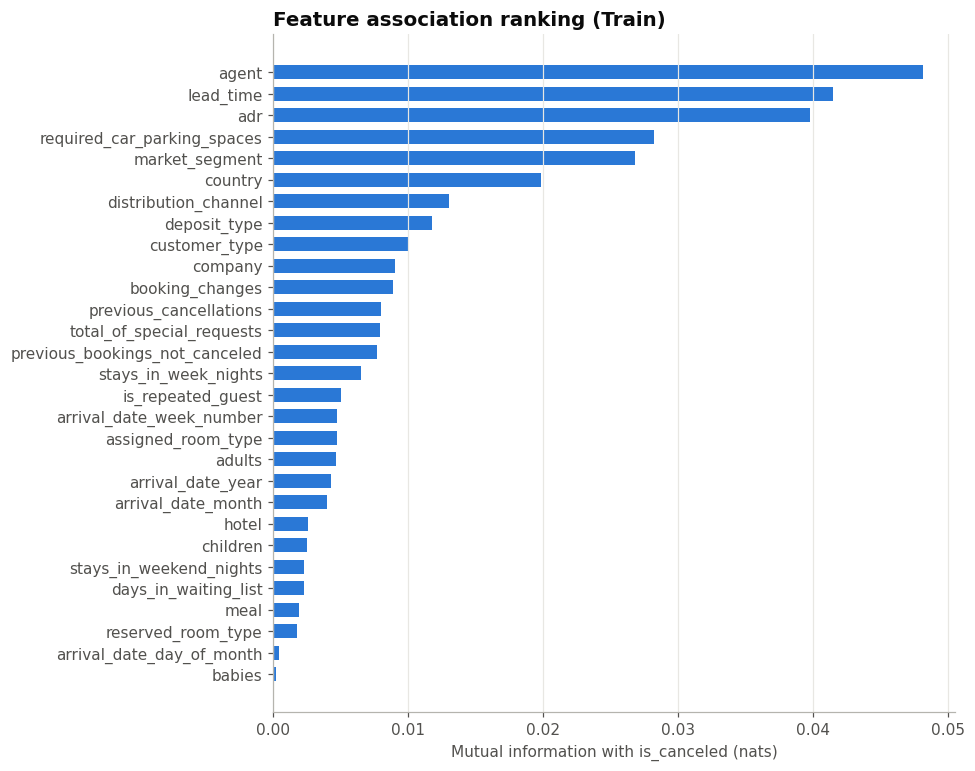

In [22]:
candidate_features = [c for c in train.columns if c not in (TARGET, ID_COLUMN)]
mi_frame = train[candidate_features].copy()
discrete_mask = []
for column in candidate_features:
    if mi_frame[column].dtype == object:
        mi_frame[column] = mi_frame[column].astype("category").cat.codes
        discrete_mask.append(True)
    else:
        discrete_mask.append(bool(pd.api.types.is_integer_dtype(mi_frame[column])))

mi_scores = pd.Series(
    mutual_info_classif(mi_frame, train[TARGET], discrete_features=np.array(discrete_mask), random_state=RANDOM_STATE),
    index=candidate_features, name="mutual_information",
).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(mi_scores.index, mi_scores.values, color=COLORS["not_canceled"], height=0.65)
ax.set_xlabel("Mutual information with is_canceled (nats)")
ax.set_title("Feature association ranking (Train)", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "mutual_information")
plt.show()
mi_scores.sort_values(ascending=False).to_frame().to_csv(PATHS["tables"] / "03_mutual_information.csv")

### 12.2 Cramér's V for categorical features
Cramér's V (bias-corrected) puts categorical associations on a 0–1 scale, which makes
them comparable across columns with different cardinality.

In [23]:
def cramers_v_corrected(x: pd.Series, y: pd.Series) -> float:
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    phi2_corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2_corr / max(1e-12, min(k_corr - 1, r_corr - 1))))


categorical_columns = [c for c in STRING_COLUMNS if c in train.columns]
cramers = pd.Series({c: cramers_v_corrected(train[c], train[TARGET]) for c in categorical_columns},
                    name="cramers_v").sort_values(ascending=False)
cramers.round(4).to_frame()

,cramers_v
agent,0.2879
market_segment,0.2238
country,0.1914
deposit_type,0.1607
distribution_channel,0.1530
customer_type,0.1339
company,0.0910
assigned_room_type,0.0898
arrival_date_month,0.0879
hotel,0.0710


### 12.3 Numeric correlation structure (Spearman)
Highly correlated numeric pairs are redundant for linear models (unstable coefficients)
and motivate engineered aggregates such as `total_nights` and `total_guests`.

Saved figure -> reports/figures/03_spearman_correlation.png


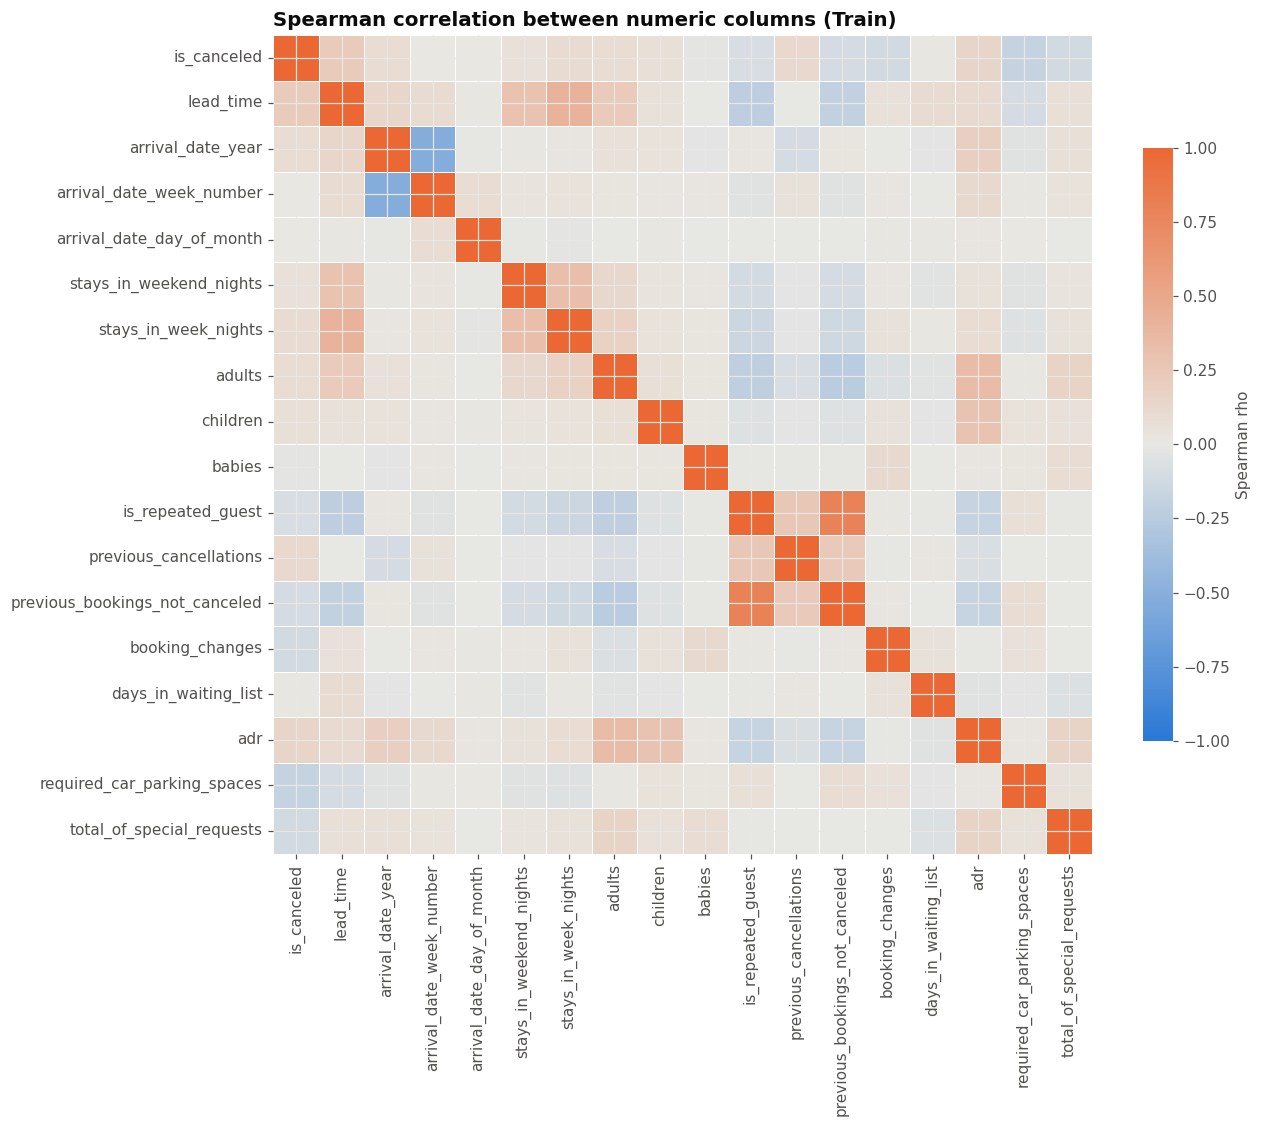

,level_0,level_1,rho,abs_rho
192,is_repeated_guest,previous_bookings_not_canceled,0.793367,0.793367
39,arrival_date_year,arrival_date_week_number,-0.517165,0.517165
24,lead_time,stays_in_week_nights,0.420362,0.420362
141,adults,adr,0.340152,0.340152
96,stays_in_weekend_nights,stays_in_week_nights,0.325127,0.325127
23,lead_time,stays_in_weekend_nights,0.295517,0.295517
159,children,adr,0.284988,0.284988
191,is_repeated_guest,previous_cancellations,0.251315,0.251315
138,adults,previous_bookings_not_canceled,-0.245258,0.245258
210,previous_cancellations,previous_bookings_not_canceled,0.240838,0.240838


In [24]:
numeric_columns = [c for c in train.select_dtypes(include="number").columns if c not in (ID_COLUMN,)]
spearman = train[numeric_columns].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(spearman, cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            linecolor="white", cbar_kws={"shrink": 0.7, "label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlation between numeric columns (Train)", loc="left")
save_figure(fig, "spearman_correlation")
plt.show()

pairs = (spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().assign(abs_rho=lambda d: d["rho"].abs())
         .sort_values("abs_rho", ascending=False).head(10))
pairs

## 13. EDA insight log
The consolidated findings (each with evidence and a modelling implication) feed
`docs/03-data-understanding.md` §3.5 and `DECISIONS.md`.

In [25]:
insight_log = pd.DataFrame(INSIGHTS)
insight_log.to_csv(PATHS["tables"] / "eda_insight_log.csv", index=False)
print(f"{len(insight_log)} insights -> reports/tables/eda_insight_log.csv")
insight_log

11 insights -> reports/tables/eda_insight_log.csv


,theme,finding,evidence,modelling_implication
0,Target,Cancellation prevalence 27.28% after de-duplic...,"16,637 of 60,996 Train bookings",Accuracy baseline is ~72.7%; report PR-AUC / r...
1,Hotel,City Hotel cancels more than Resort Hotel,City Hotel: 29.8%; Resort Hotel: 23.3%,Keep `hotel`; consider hotel-specific threshol...
2,Lead time,Cancellation rate increases monotonically with...,8.3% (0-7d) -> 40.3% (>365d),Keep raw lead_time (trees) and scale it for li...
3,Deposit,Non Refund deposits show a near-deterministic ...,Non Refund: 94.8% (n=678),Keep feature but report as a probable channel/...
4,History,Guests with a prior cancellation cancel far mo...,Yes: 67.0% vs No: 26.5%,Keep previous_cancellations; engineer prior_ca...
5,History,Repeat guests cancel less,Repeat: 7.6% vs New: 28.1%,Keep is_repeated_guest.
6,Leakage audit,required_car_parking_spaces > 0 has ~0% cancel...,"0 cancellations in 5,126 bookings",Probable arrival-time field: exclude from day-...
7,Leakage audit,Room re-assignment is associated with far fewe...,Changed: 4.6% vs Same: 31.3%,Re-assignment usually happens at check-in: ful...
8,Leakage audit,PRT bookings cancel more often than all other ...,PRT: 35.4% vs Other: 23.6%,Possible late-recorded nationality; run a with...
9,Engagement,Cancellation rate falls as special requests in...,0: 32.7%; 1: 22.4%; 2: 21.4%; 3+: 17.1%,Keep total_of_special_requests (note: requests...


## 14. Hand-off summary
- **For notebook 04:** engineered-feature motivation (lead time, guest history,
  totals) and the leakage-suspect list: parking → day-zero exclusion; room change,
  booking changes and waiting list → full-lifecycle only; `arrival_date_year` → excluded.
- **For notebooks 10 and 13:** the country/PRT hypothesis for the fairness and
  ablation analysis; the deposit-type confound for the limitations section.